In [2]:
#making the necessary imports 

import pandas as pd  # loads and manipulates the csv dataset
import matplotlib.pyplot as plt  # creates graphs and charts 
import seaborn as sns  # creates heatmaps and confusion matrix visualizations
from sklearn.model_selection import train_test_split # divides data into training and testing sets 
from sklearn.linear_model import LogisticRegression # classification using a logistic regression model
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score # evaluation metrics
from sklearn.neighbors import KNeighborsClassifier # predicts using nearby training samples
from sklearn.tree import DecisionTreeClassifier # classifies using decision rules
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier #combines multiple decision trees
#bagging: combines predictions from multiple models trained on different samples
from sklearn.multiclass import OneVsRestClassifier #trains one classifier per class against the remaining classes
from sklearn.svm import SVC #support vector machine classifier 
from sklearn.naive_bayes import GaussianNB # naive bayes classification using a gaussian distribution assumption
from sklearn.preprocessing import LabelEncoder # converts categorical labels into numeric labels

In [3]:
# read the csv file and to check the features use head function
lung_data = pd.read_csv("survey_lung_cancer.csv") # loads csv file into pandas df
lung_data.head() # displays first 5 rows by default

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,MALE,69,0,1,1,0,0,1,0,1,1,1,1,1,1,YES
1,MALE,74,1,0,0,0,1,1,1,0,0,0,1,1,1,YES
2,FEMALE,59,0,0,0,1,0,1,0,1,0,1,1,0,1,NO
3,MALE,63,1,1,1,0,0,0,0,0,1,0,0,1,1,NO
4,FEMALE,63,0,1,0,0,0,0,0,1,0,1,1,0,0,NO


In [4]:
# convert gender : male - 0 female - 1 and lung cancer : yes  - 1 and no: 0
lung_data["GENDER"]=lung_data["GENDER"].map({"MALE":0, "FEMALE":1})
lung_data["LUNG_CANCER"]=lung_data["LUNG_CANCER"].map({"YES":1 , "NO": 0})
lung_data.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,0,69,0,1,1,0,0,1,0,1,1,1,1,1,1,1
1,0,74,1,0,0,0,1,1,1,0,0,0,1,1,1,1
2,1,59,0,0,0,1,0,1,0,1,0,1,1,0,1,0
3,0,63,1,1,1,0,0,0,0,0,1,0,0,1,1,0
4,1,63,0,1,0,0,0,0,0,1,0,1,1,0,0,0


In [5]:
#check the dataset shape
lung_data.shape


(309, 16)

In [6]:
#independent variable (here x depends on y)
x = lung_data.iloc[:,0:-1] # selects every column except the last one 
# this is safe only if lung_cancer is actually the last column
x

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN
0,0,69,0,1,1,0,0,1,0,1,1,1,1,1,1
1,0,74,1,0,0,0,1,1,1,0,0,0,1,1,1
2,1,59,0,0,0,1,0,1,0,1,0,1,1,0,1
3,0,63,1,1,1,0,0,0,0,0,1,0,0,1,1
4,1,63,0,1,0,0,0,0,0,1,0,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
304,1,56,0,0,0,1,1,1,0,0,1,1,1,1,0
305,0,70,1,0,0,0,0,1,1,1,1,1,1,0,1
306,0,58,1,0,0,0,0,0,1,1,1,1,0,0,1
307,0,67,1,0,1,0,0,1,1,0,1,1,1,0,1


In [7]:
#dependent variable 
y = lung_data["LUNG_CANCER"]
y = y.values.ravel()
y

array([1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1,
       0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [8]:
# splitting the dataset 
dependent_var = lung_data.iloc[:,0:-1] #features (everything except the last one)
independent_var = lung_data.iloc[:, -1] # target
x_train, x_test, y_train, y_test = train_test_split(dependent_var,independent_var,test_size=1/3,random_state=0)

In [ ]:
#logistic regression 
log_reg = LogisticRegression(max_iter=200) #creates a model which allows up to 200 optimization iterations
log_reg.fit(x_train,y_train) # learn patterns from the training data

#predicting the test set results 
prediction1 = log_reg.predict(x_test) # generates the predictions for the test data
prediction1

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1,
       1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [ ]:
#KNN Classifier
#knn examines the 3 nearest training examples and predicts the class based on their lables
#p=2 with minkowski metric means euclidean distance
knn = KNeighborsClassifier(n_neighbors=3 , metric='minkowski', p=2)
knn.fit(x_train,y_train)
prediction2 = knn.predict(x_test)
prediction2

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [ ]:
#decision tree
#Decision tree learns rules that split the data into groups
tree = DecisionTreeClassifier(random_state=0 , criterion="entropy")
tree.fit(x_train,y_train)
prediction3 = tree.predict(x_test)
prediction3

array([1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1,
       1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1])

In [ ]:
#svm classifier 
#kernel = 'rbf' can model non linear decision boundaries
# c controls the trade off between classification errors on the training set and a simpler decision boundary
svm = OneVsRestClassifier(BaggingClassifier(SVC(C=10, kernel='rbf', random_state=9, probability=True), n_jobs=-1))
svm.fit(x_train, y_train)
prediction4 = svm.predict(x_test)
prediction4

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [12]:
#naive bayes 
nb = GaussianNB()
nb.fit(x_train,y_train)
prediction5 = nb.predict(x_test)
prediction5

array([1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1,
       1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [ ]:
#random forest
# trains 100 decision trees by default in this example and combines their predictions
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(x_train,y_train)
prediction6=rf_classifier.predict(x_test)
prediction6

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1,
       1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [ ]:
# evaluation function
#accuracy : fraction of all test predictions that are correct
#precision : of the cases predicted as positive how many are actually positive
# recall : of the actual +Ve cases, how many did the model identify
# f1-score: harmonic mean of precision and recall
def evaluate_model(y_true, y_pred, model_name, results_dict):
    accuracy = accuracy_score(y_true,y_pred)
    precision = precision_score(y_true,y_pred)
    recall = recall_score(y_true, y_pred)
    f1=f1_score(y_true,y_pred)

    #store results in dictionary
    results_dict[model_name] = accuracy

    print(f"{model_name} Metrics:")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall : {recall:.4f}")
    print(f"F1 score : {f1:.4f}\n")

In [17]:
#dictionary to store accurate results

accuracy_results = {}

#evaluate each model
evaluate_model(y_test, prediction1, "LogisticRegression", accuracy_results)
evaluate_model(y_test, prediction2, "KNN", accuracy_results)
evaluate_model(y_test, prediction3, "Decision Tree", accuracy_results)
evaluate_model(y_test, prediction4, "SVM", accuracy_results)
evaluate_model(y_test, prediction5, "Naive Bayes", accuracy_results)
evaluate_model(y_test, prediction6, "Random Forest", accuracy_results)



LogisticRegression Metrics:
Accuracy : 0.9029
Precision : 0.9140
Recall : 0.9770
F1 score : 0.9444

KNN Metrics:
Accuracy : 0.8738
Precision : 0.8776
Recall : 0.9885
F1 score : 0.9297

Decision Tree Metrics:
Accuracy : 0.8641
Precision : 0.9195
Recall : 0.9195
F1 score : 0.9195

SVM Metrics:
Accuracy : 0.8447
Precision : 0.8447
Recall : 1.0000
F1 score : 0.9158

Naive Bayes Metrics:
Accuracy : 0.8641
Precision : 0.9101
Recall : 0.9310
F1 score : 0.9205

Random Forest Metrics:
Accuracy : 0.8932
Precision : 0.9043
Recall : 0.9770
F1 score : 0.9392



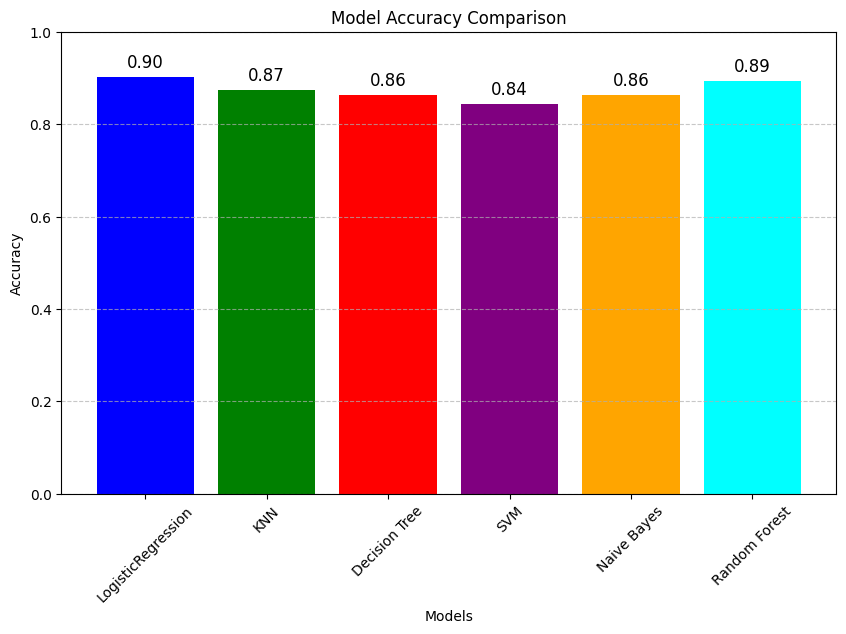

In [18]:
# plot accuracy of all models
plt.figure(figsize=(10,6))
plt.bar(accuracy_results.keys(), accuracy_results.values(), color=['blue','green','red','purple','orange','cyan'])
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.ylim(0,1)
plt.title("Model Accuracy Comparison")
plt.xticks(rotation=45)
plt.grid(axis = 'y', linestyle = '--', alpha=0.7)

#show accuracy values on top of bars
for i, (model,acc) in enumerate(accuracy_results.items()):
    plt.text(i, acc + 0.02, f"{acc:.2f}" , ha="center", fontsize=12)

plt.show()

In [19]:
#confusion matrix plotting
def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, cmap="Blues", fmt="d")
    plt.xlabel("Predicted Labels")
    plt.ylabel("True Labels")
    plt.title(f"{model_name} - Confusion Matrix")
    plt.show()

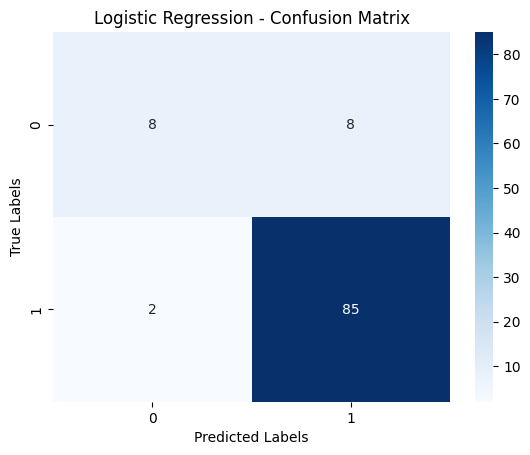

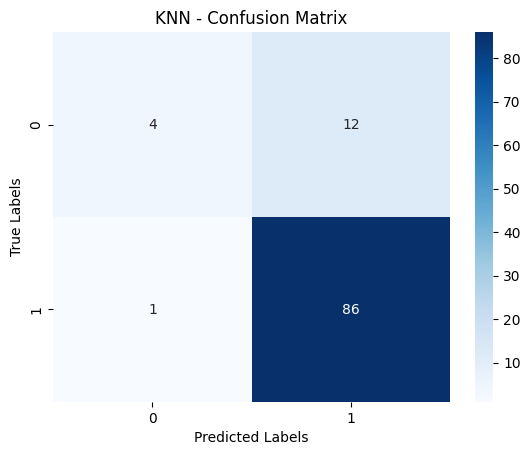

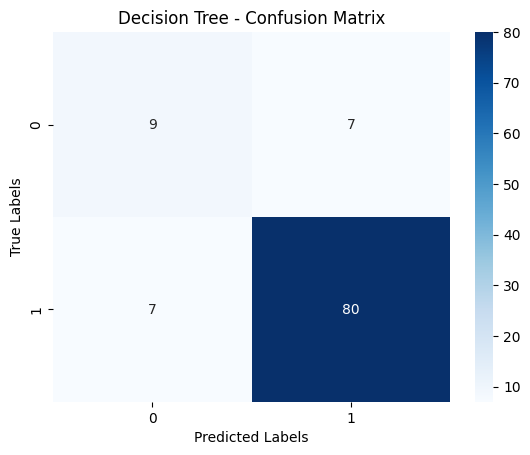

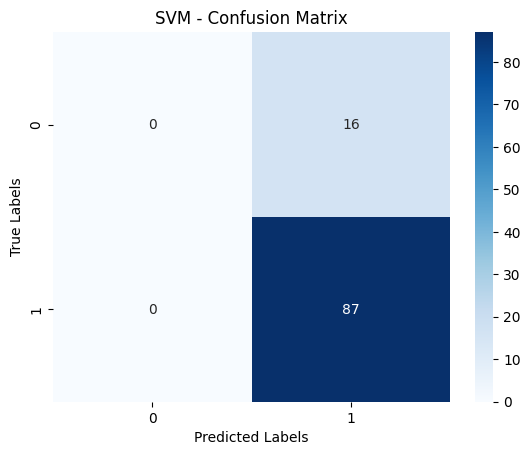

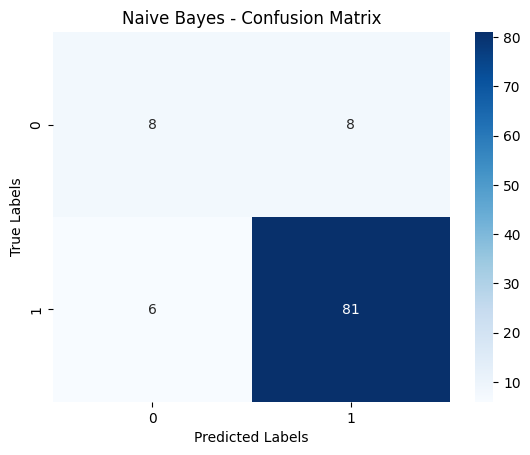

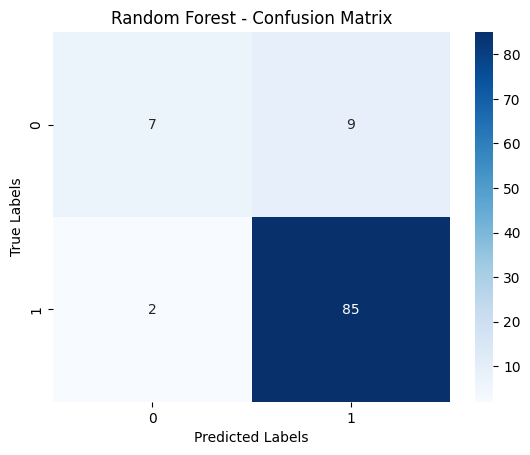

In [20]:
#confusion matrix visualization
plot_confusion_matrix(y_test, prediction1, "Logistic Regression")
plot_confusion_matrix(y_test, prediction2, "KNN")
plot_confusion_matrix(y_test, prediction3, "Decision Tree")
plot_confusion_matrix(y_test, prediction4, "SVM")
plot_confusion_matrix(y_test, prediction5, "Naive Bayes")
plot_confusion_matrix(y_test, prediction6, "Random Forest")

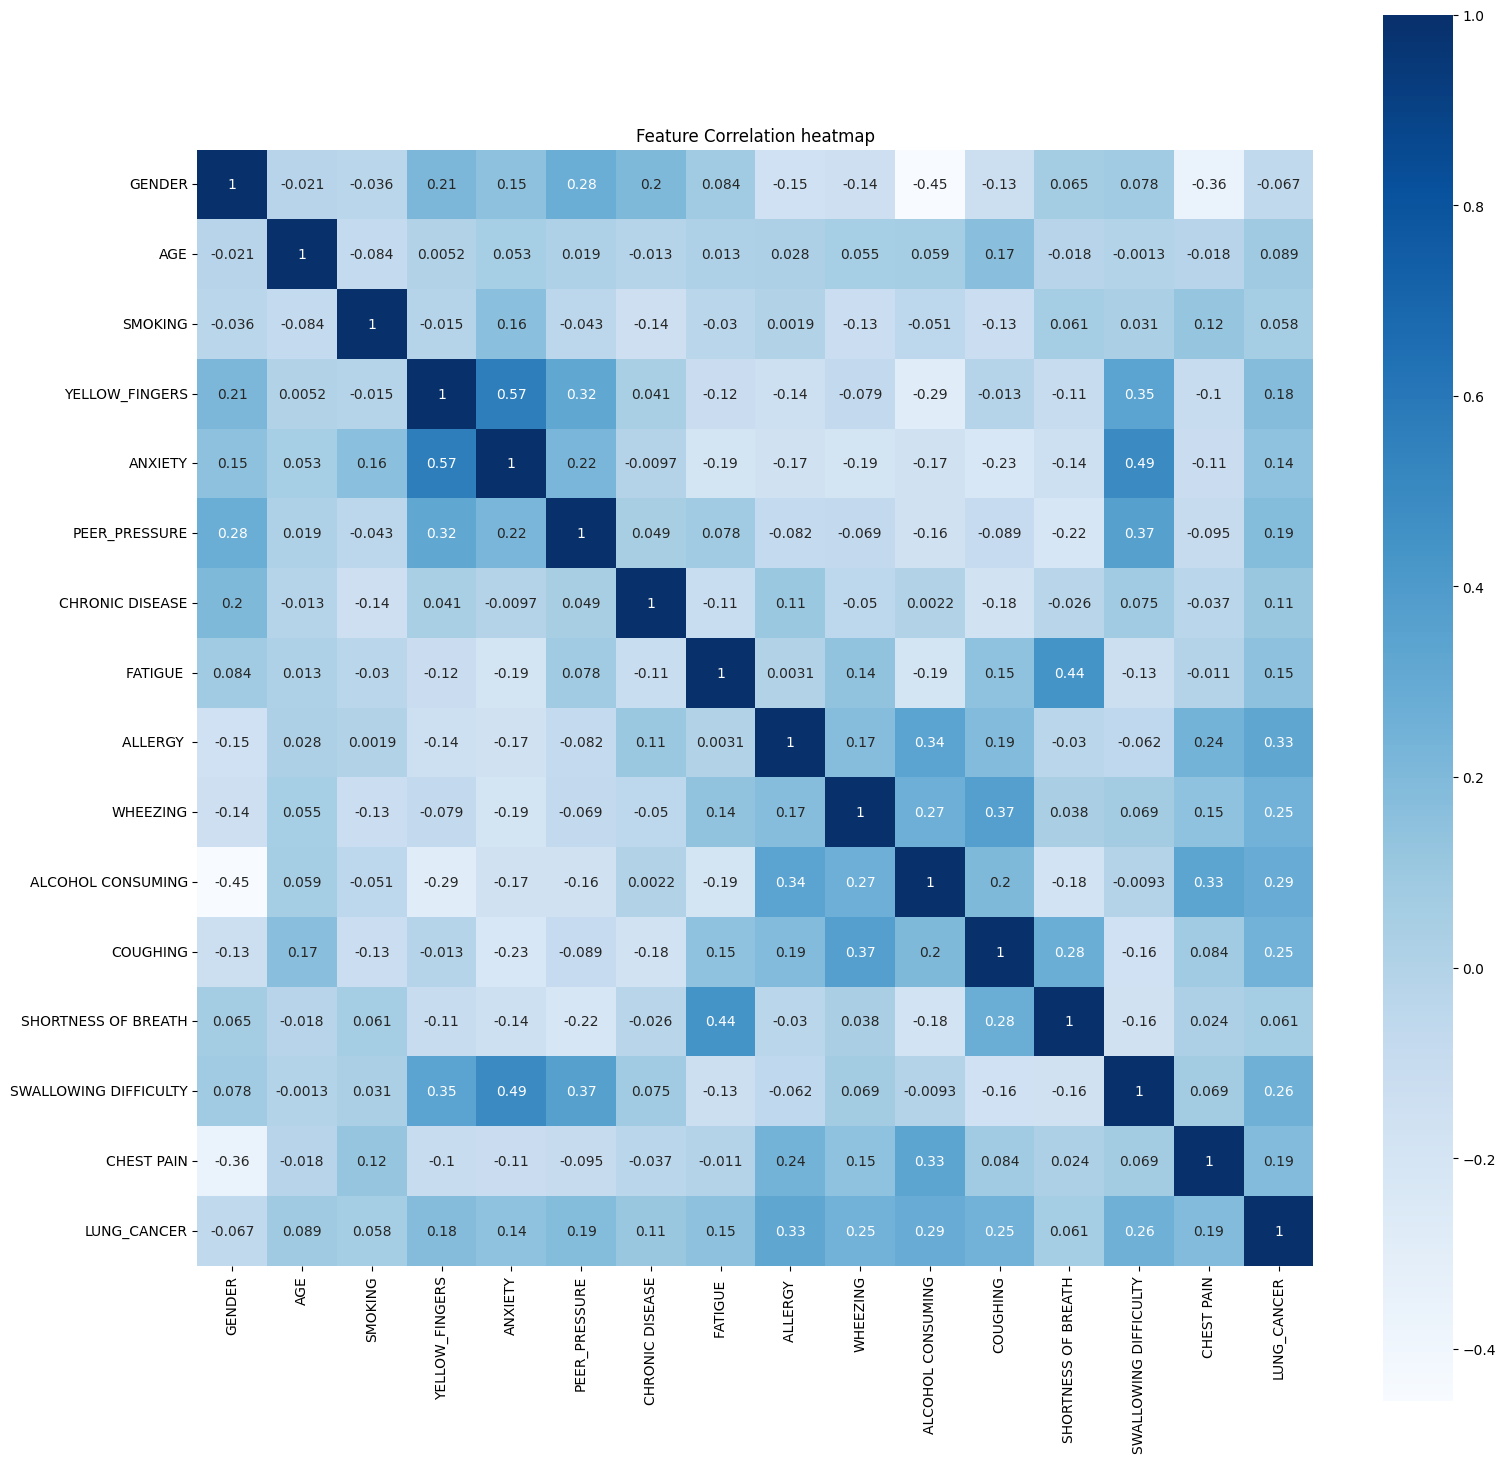

In [21]:
#corelation heatmap
corelation = lung_data.corr()
plt.figure(figsize=(18,18))
sns.heatmap(corelation, cmap="Blues", annot=True, square=True)
plt.title("Feature Correlation heatmap")
plt.show()

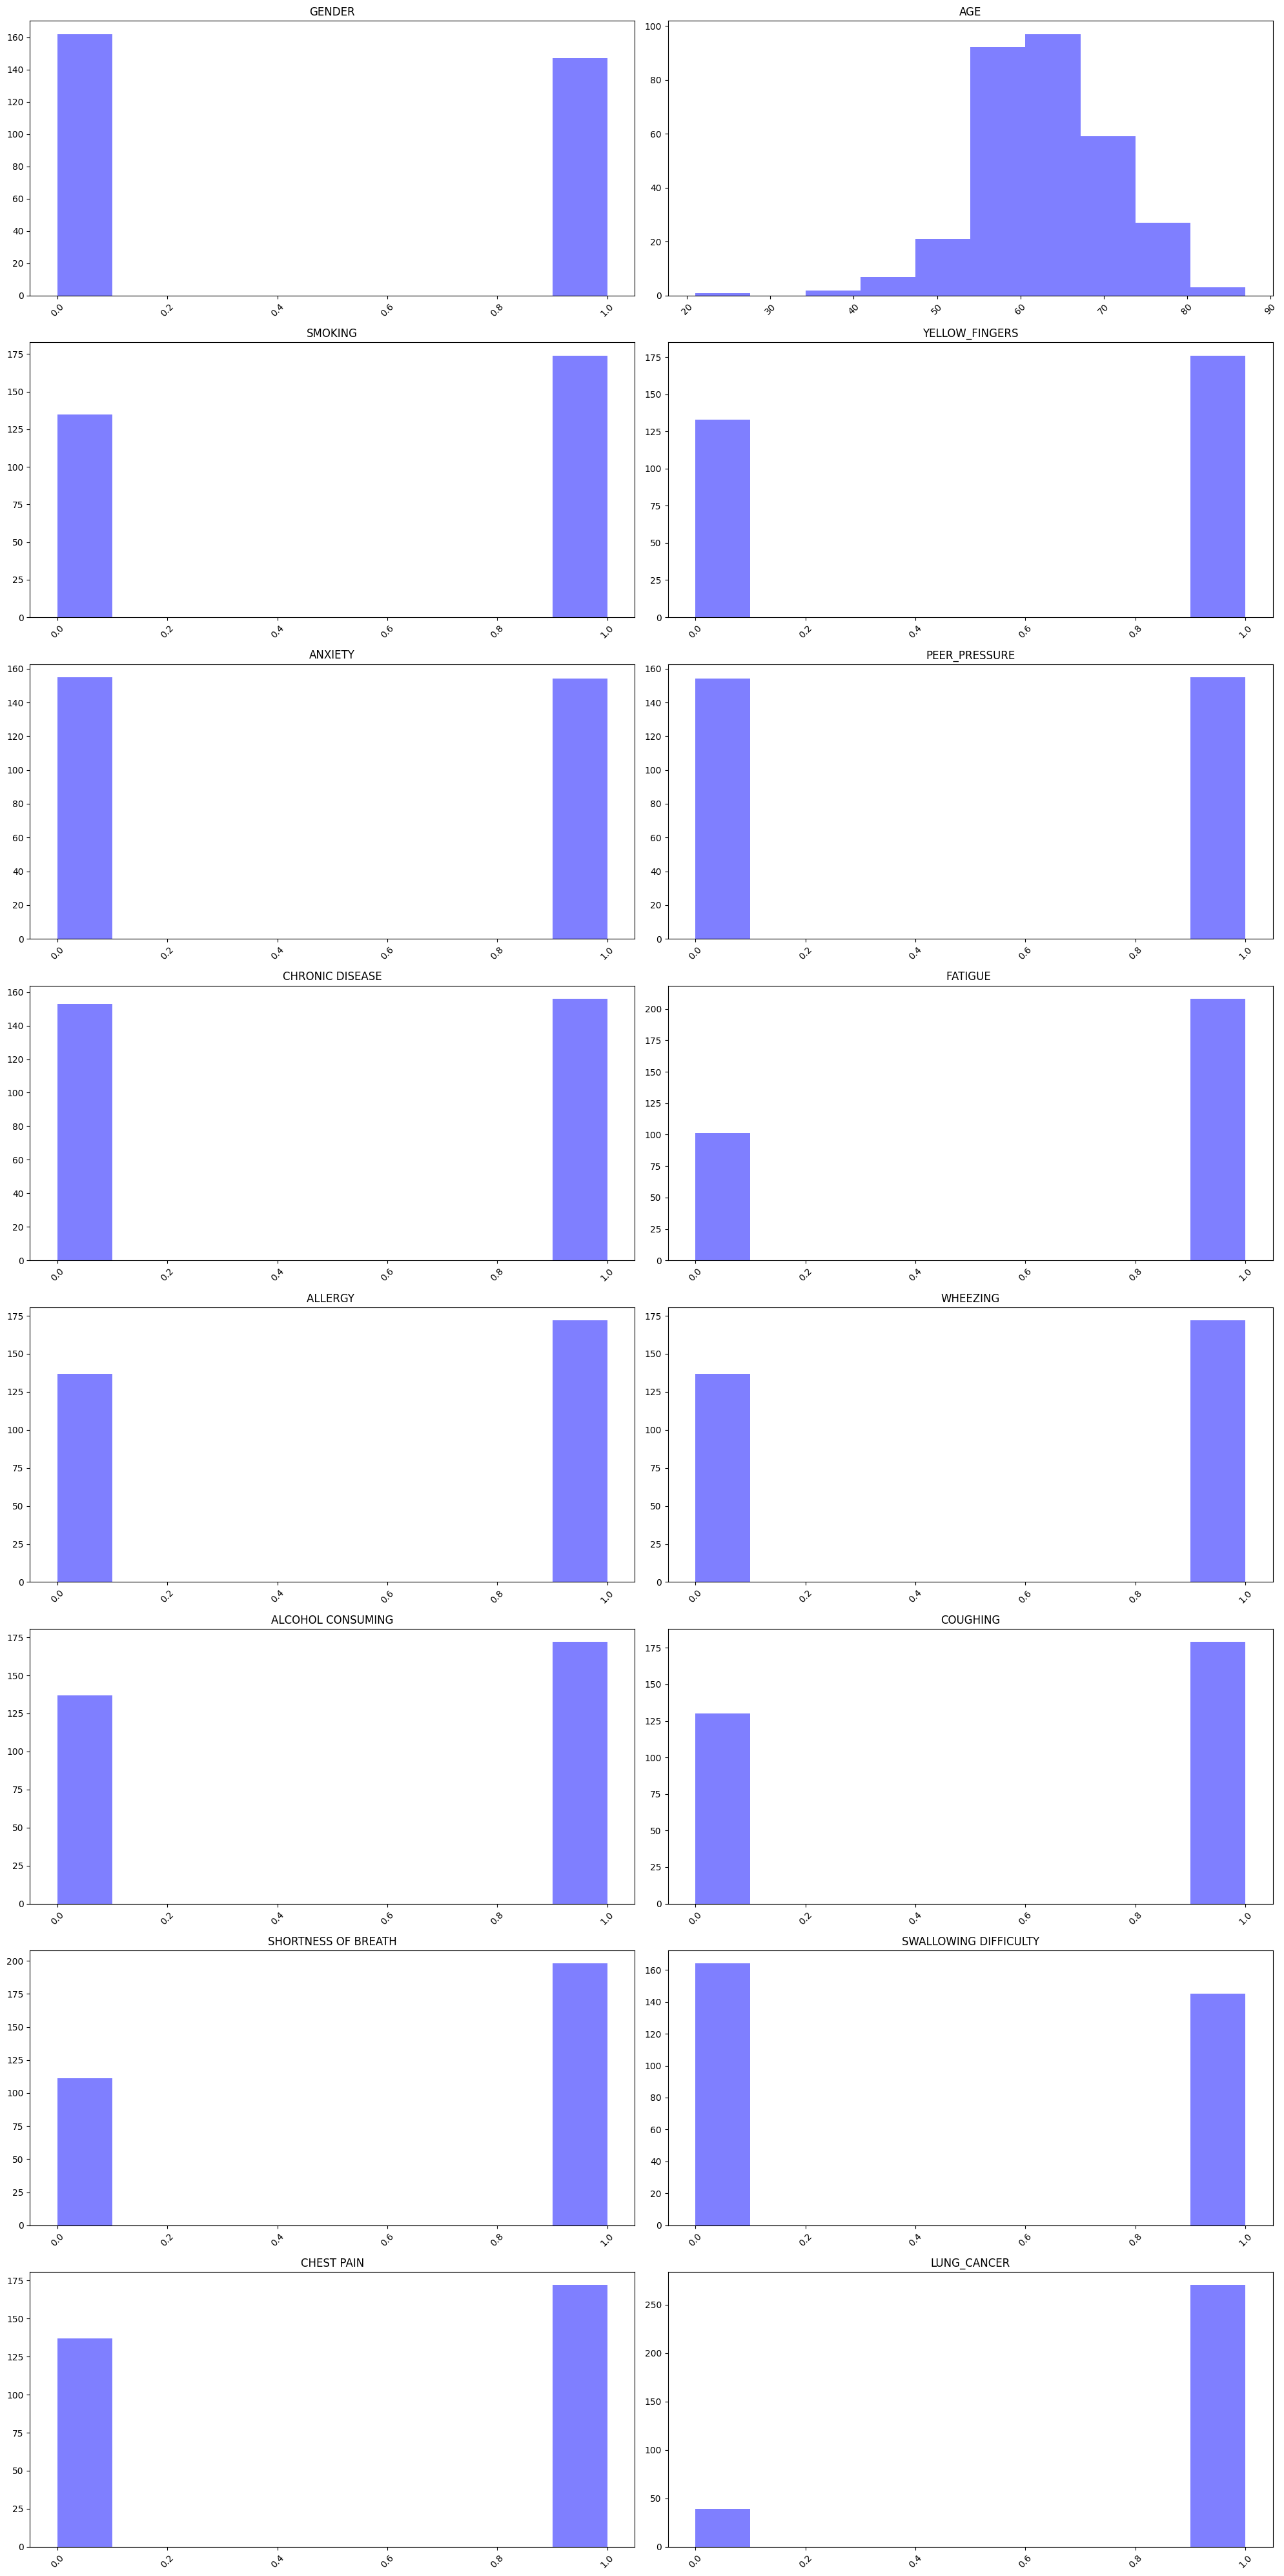

In [22]:
#feature distribution
num_list = list(lung_data.columns)
rows = (len(num_list) //2) + (len(num_list) % 2)

#set figure size
plt.figure(figsize=(20,40))
for i in range(len(num_list)):
    plt.subplot(rows, 2, i+1)
    plt.title(num_list[i])
    plt.xticks(rotation=45)
    plt.hist(lung_data[num_list[i]],color='blue',alpha=0.5)

plt.tight_layout()
plt.show()